# Ames Housing: ML EDA

Dataset: Ames, Iowa home sales 2006-2010 (OpenML #42165, De Cock 2011). Target: `SalePrice`.


## 1.1 Load and look

In [1]:
import pandas as pd
#show all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [2]:

df = pd.read_csv("data/ames_house_prices.csv", keep_default_na=False, na_values=[""])
print(df.shape)   # expected: (1460, 81)
print(df.head(3))
df.reset_index(drop=True, inplace=True)

(1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   

  LandContour Utilities LotConfig LandSlope Neighborhood Condition1  \
0         Lvl    AllPub    Inside       Gtl      CollgCr       Norm   
1         Lvl    AllPub       FR2       Gtl      Veenker      Feedr   
2         Lvl    AllPub    Inside       Gtl      CollgCr       Norm   

  Condition2 BldgType HouseStyle  OverallQual  OverallCond  YearBuilt  \
0       Norm     1Fam     2Story            7            5       2003   
1       Norm     1Fam     1Story            6            8       1976   
2       Norm     1Fam     2Story            7            5       2001   

   YearRemodAdd RoofStyle RoofMatl Exterior1st Exterior2nd MasVnrType  \
0          2003     Gable  CompShg     Vi

/var/folders/9t/d8g879bj5ss5s1jty3frvvww0000gn/T/ipykernel_12341/2427052807.py:4: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)


In [3]:
table1 = pd.DataFrame({'columns': [col for col in df.columns], 'data_types': [df[col].dtype for col in df.columns], 'missing_values': [df[col].isnull().sum() for col in df.columns],'missing_value_percentage': [round(df[col].isnull().sum() / len(df) * 100, 2) for col in df.columns], 'num_unique_values': [df[col].nunique() for col in df.columns], 'num_zero_values': [df[col].isin([0]).sum() for col in df.columns], 'num_empty_strings': [df[col].isin(['']).sum() for col in df.columns],'data_type_category': [df[col].dtype.name for col in df.columns]})
display(table1.sort_values(by=['missing_value_percentage'], ascending=False))

,columns,data_types,missing_values,missing_value_percentage,num_unique_values,num_zero_values,num_empty_strings,data_type_category
72,PoolQC,str,1453,99.52,3,0,0,str
74,MiscFeature,str,1406,96.30,4,0,0,str
6,Alley,str,1369,93.77,2,0,0,str
73,Fence,str,1179,80.75,4,0,0,str
57,FireplaceQu,str,690,47.26,5,0,0,str
3,LotFrontage,float64,259,17.74,110,0,0,float64
59,GarageYrBlt,float64,81,5.55,97,0,0,float64
64,GarageCond,str,81,5.55,5,0,0,str
58,GarageType,str,81,5.55,6,0,0,str
60,GarageFinish,str,81,5.55,3,0,0,str


In [4]:
df.dtypes

Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
Street               str
Alley                str
LotShape             str
LandContour          str
Utilities            str
LotConfig            str
LandSlope            str
Neighborhood         str
Condition1           str
Condition2           str
BldgType             str
HouseStyle           str
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
RoofStyle            str
RoofMatl             str
Exterior1st          str
Exterior2nd          str
MasVnrType           str
MasVnrArea       float64
ExterQual            str
ExterCond            str
Foundation           str
BsmtQual             str
BsmtCond             str
BsmtExposure         str
BsmtFinType1         str
BsmtFinSF1         int64
BsmtFinType2         str
BsmtFinSF2         int64
BsmtUnfSF          int64
TotalBsmtSF        int64
Heating              str


In [5]:
data_type_table = pd.DataFrame({'columns Name':[col for col in df.columns], 'data_type': [df[col].dtype for col in df.columns]})
display(data_type_table)

,columns Name,data_type
0,Id,int64
1,MSSubClass,int64
2,MSZoning,str
3,LotFrontage,float64
4,LotArea,int64
5,Street,str
6,Alley,str
7,LotShape,str
8,LandContour,str
9,Utilities,str


In [6]:
missing_table = pd.DataFrame({'columns': [col for col in df.columns], 'missing_values': [df[col].isnull().sum() for col in df.columns],'missing_value_percentage': [round(df[col].isnull().sum() / len(df) * 100, 2) for col in df.columns]})
display(missing_table[missing_table['missing_value_percentage'] > 0].sort_values(by=['missing_value_percentage'], ascending=False))

,columns,missing_values,missing_value_percentage
72,PoolQC,1453,99.52
74,MiscFeature,1406,96.30
6,Alley,1369,93.77
73,Fence,1179,80.75
57,FireplaceQu,690,47.26
3,LotFrontage,259,17.74
58,GarageType,81,5.55
59,GarageYrBlt,81,5.55
60,GarageFinish,81,5.55
63,GarageQual,81,5.55


In [7]:
table2= pd.crosstab(df['PoolQC'].isnull(), df['PoolArea'])
display(table2)

PoolArea,0,480,512,519,555,576,648,738
PoolQC,,,,,,,,
False,0,1,1,1,1,1,1,1
True,1453,0,0,0,0,0,0,0


In [8]:
df.PoolQC = df.PoolQC.fillna('No Pool')

In [9]:
missing_table = pd.DataFrame({'columns': [col for col in df.columns], 'missing_values': [df[col].isnull().sum() for col in df.columns],'missing_value_percentage': [round(df[col].isnull().sum() / len(df) * 100, 2) for col in df.columns]})
display(missing_table[missing_table['missing_value_percentage'] > 0].sort_values(by=['missing_value_percentage'], ascending=False))

,columns,missing_values,missing_value_percentage
74,MiscFeature,1406,96.30
6,Alley,1369,93.77
73,Fence,1179,80.75
57,FireplaceQu,690,47.26
3,LotFrontage,259,17.74
58,GarageType,81,5.55
59,GarageYrBlt,81,5.55
60,GarageFinish,81,5.55
63,GarageQual,81,5.55
64,GarageCond,81,5.55


In [10]:
Table5= pd.crosstab(df['GarageType'].isnull(), df['MiscFeature'])
display(Table5)

MiscFeature,Gar2,Othr,Shed,TenC
GarageType,,,,
False,2,1,47,1
True,0,1,2,0


In [11]:
df.Fence = df.Fence.fillna('No Fence')

In [12]:
df.Alley = df.Alley.fillna('No Alley access')

In [13]:
table3= pd.crosstab(df['FireplaceQu'].isnull(), df['Fireplaces'])
display(table3)
print(table3)

Fireplaces,0,1,2,3
FireplaceQu,,,,
False,0,650,115,5
True,690,0,0,0


Fireplaces     0    1    2  3
FireplaceQu                  
False          0  650  115  5
True         690    0    0  0


In [14]:
df.FireplaceQu = df.FireplaceQu.fillna('No Fireplace')

In [15]:
table4= pd.crosstab(df['LotFrontage'].isnull(), df['LotConfig'])
display(table4)

LotConfig,Corner,CulDSac,FR2,FR3,Inside
LotFrontage,,,,,
False,201,45,33,4,918
True,62,49,14,0,134


In [16]:
garage_cols = ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]
df[garage_cols] = df[garage_cols].fillna("No Garage")

bsmt_cols = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
no_bsmt = df["TotalBsmtSF"] == 0          # the 37 houses with no basement
for c in bsmt_cols:
    df.loc[no_bsmt, c] = df.loc[no_bsmt, c].fillna("No Basement")

In [17]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [18]:
pd.crosstab(df.MiscFeature.isna(),df.MiscVal)

MiscVal,0,54,350,400,450,480,500,560,600,620,700,800,1150,1200,1300,1400,2000,2500,3500,8300,15500
MiscFeature,,,,,,,,,,,,,,,,,,,,,
False,2,1,1,11,4,2,8,1,4,1,5,1,1,2,1,1,4,1,1,1,1
True,1406,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [19]:
df.MiscFeature = df.MiscFeature.fillna('No MiscFeature')

In [20]:
pd.crosstab(df.GarageYrBlt.isna(),df.GarageFinish)

GarageFinish,Fin,No Garage,RFn,Unf
GarageYrBlt,,,,
False,352,0,422,605
True,0,81,0,0


In [21]:
cat_features = ['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle','RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical','KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC','Fence','MiscFeature','SaleType','SaleCondition']
for col in cat_features:
    df[col] = df[col].astype('category')

In [22]:
y=df['SalePrice']
X=df.drop(['SalePrice', 'SaleType', 'SaleCondition', 'Id'], axis=1)
final_feature_target_table = pd.DataFrame({'Features':[X.shape[1]],'Observations':[X.shape[0]],'Target':[y.shape[0]]})
display(final_feature_target_table.style.hide(axis='index'))

Features,Observations,Target
77,1460,1460


In [23]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}, Train target shape: {y_train.shape}, Test target shape: {y_test.shape}")

Train shape: (1168, 77), Test shape: (292, 77), Train target shape: (1168,), Test target shape: (292,)


## 1.1 Split features (X) from target (y)

In [26]:
Summary_y = pd.concat([y_train.describe().T, y_test.describe().T], axis=1, keys=['Train', 'Test'])
display(Summary_y.style.format("{:.2f}"))

,Train,Test
count,1168.00,292.00
mean,181441.54,178839.81
std,77263.58,87730.75
min,34900.00,35311.00
25%,130000.00,127000.00
50%,165000.00,154150.00
75%,214925.00,209175.00
max,745000.00,755000.00


1.743128561420854
0.124879509423823


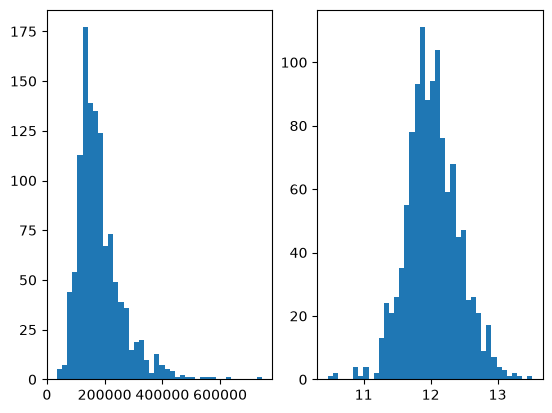

In [27]:
import numpy as np
import matplotlib.pyplot as plt
print(y_train.skew())                    # 1.74 (train)
print(np.log(y_train).skew())            # 0.12
fig, ax = plt.subplots(1, 2)             # two panels
ax[0].hist(y_train, bins=40)             # raw: long right tail
ax[1].hist(np.log(y_train), bins=40) 
plt.show()    # log: bell-shaped

In [28]:
y_train_log = np.log(y_train); y_test_log = np.log(y_test)
print("Skewness of y_train_log:", round(y_train_log.skew(), 2)); print("Skewness of y_test_log:", round(y_test_log.skew(), 2))
print("Mean of y_train_log:", round(y_train_log.mean(), 2)); print("Mean of y_test_log:", round(y_test_log.mean(), 2))

Skewness of y_train_log: 0.12
Skewness of y_test_log: 0.14
Mean of y_train_log: 12.03
Mean of y_test_log: 12.0


In [29]:
m = X_train.isna().sum()
print(m[m > 0].sort_values(ascending=False))   # 5 columns left in train, LotFrontage on top

LotFrontage    217
GarageYrBlt     64
MasVnrType       6
MasVnrArea       6
Electrical       1
dtype: int64


## 1.1 Leak hunt: which columns would a seller not know before the sale?

In [30]:
num_features = X_train.select_dtypes(include='number')
print(round(num_features.corrwith(y_train_log).sort_values(ascending=False), 2))


OverallQual      0.81
GrLivArea        0.69
GarageCars       0.68
GarageArea       0.65
TotalBsmtSF      0.60
FullBath         0.58
1stFlrSF         0.58
YearBuilt        0.58
YearRemodAdd     0.56
GarageYrBlt      0.53
TotRmsAbvGrd     0.52
Fireplaces       0.48
MasVnrArea       0.42
BsmtFinSF1       0.34
WoodDeckSF       0.34
LotFrontage      0.33
2ndFlrSF         0.31
HalfBath         0.31
OpenPorchSF      0.31
LotArea          0.26
BsmtUnfSF        0.24
BsmtFullBath     0.23
BedroomAbvGr     0.19
ScreenPorch      0.12
PoolArea         0.08
3SsnPorch        0.06
MoSold           0.06
BsmtFinSF2       0.01
YrSold          -0.02
MiscVal         -0.02
LowQualFinSF    -0.02
BsmtHalfBath    -0.03
OverallCond     -0.03
KitchenAbvGr    -0.16
EnclosedPorch   -0.17
dtype: float64


In [ ]:
for col in num_features.corrwith(y_train_log).abs().sort_values(ascending=False).index[:6]:
    plt.scatter(X_train[col], y_train_log, alpha=0.5)
    plt.title(f"Scatter plot of {col} vs SalePrice (log)")
    plt.xlabel(col)
    plt.ylabel("SalePrice (log)")
    plt.show()

### My notes

